# Voice Scribe — EDA of the English benchmark v1.1

What the speech-to-text models will face, and the scoring decisions that follow from it.

- Run from `benchmark_v1/eda/`. Needs: `pip install numpy pandas matplotlib soundfile wordfreq`
- Figures go to `eda/figures/`, tables to `eda/tables/`.
- **Rule:** describing the whole set is fine; any *decision* (scoring rules, exclusions) is made from the **dev** split only.

In [1]:
from pathlib import Path
import json, re, collections
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from wordfreq import zipf_frequency

DATA = Path('..') / 'data'          # benchmark_v1/data
FIG, TAB = Path('figures'), Path('tables'); FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 120)

# chart style: categorical hues in fixed order, recessive grid, text in ink colours
S = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 11,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 150,
    'savefig.bbox': 'tight'})

eka = pd.read_csv(DATA / 'eka_en/manifest.csv')
sv = pd.read_csv(DATA / 'svarah/manifest.csv')
utt = pd.read_csv(DATA / 'primock57/manifest_utterances.csv')
con = pd.read_csv(DATA / 'primock57/manifest_consultations.csv')
noisy = pd.read_csv(DATA / 'primock57/manifest_noisy.csv')
refs = {p.stem: json.load(open(p, encoding='utf-8')) for p in sorted((DATA / 'primock57/references').glob('*.json'))}
utt['duration_seconds'] = utt.end_s - utt.start_s
for d in (eka, sv, utt): d['n_words'] = d.transcript_norm.fillna('').str.split().str.len()
print(len(eka), len(sv), len(utt), len(con), len(noisy))

3619 6656 6551 57 570


## 1. Size and balance

In [2]:
def summ(d, name, unit='clips', spk='speaker_id'):
    g = d.groupby('split')
    out = pd.DataFrame({'dataset': name, unit: g.size(), 'hours': g.duration_seconds.sum() / 3600,
                        'speakers': g[spk].apply(lambda x: x[x != UNKNOWN_SPK].nunique()) if spk else np.nan,
                        'median_s': g.duration_seconds.median(), 'words': g.n_words.sum()})
    return out.reset_index()
con['n_words'] = con.n_words_ref
# Eka's 110 conversation clips have no speaker id in the source; they share one placeholder id, which is not a person
UNKNOWN_SPK = eka.loc[eka.recording_context == 'conversation', 'speaker_id'].iloc[0]
print('Eka placeholder id for unknown conversation speakers (not counted as a speaker):', UNKNOWN_SPK)
overview = pd.concat([summ(con, 'PriMock57 consultations', 'items', None), summ(utt, 'PriMock57 utterances', 'items', None),
                      summ(eka, 'Eka Medical ASR (en)', 'items'), summ(sv, 'Svarah', 'items')])
overview = overview.round({'hours': 2, 'median_s': 1}); overview.to_csv(TAB / '01_overview.csv', index=False); overview

Eka placeholder id for unknown conversation speakers (not counted as a speaker): eka_spk_22


,split,dataset,items,hours,speakers,median_s,words
0,dev,PriMock57 consultations,11,1.67,NaN,579.4,15955
1,test,PriMock57 consultations,46,6.96,NaN,551.8,65328
0,dev,PriMock57 utterances,1285,1.62,NaN,3.4,15955
1,test,PriMock57 utterances,5266,6.65,NaN,3.4,65328
0,dev,Eka Medical ASR (en),735,1.63,11.0,4.3,11285
1,test,Eka Medical ASR (en),2884,6.78,45.0,5.0,43406
0,dev,Svarah,1351,2.18,19.0,5.0,15267
1,test,Svarah,5305,7.44,96.0,4.0,54207


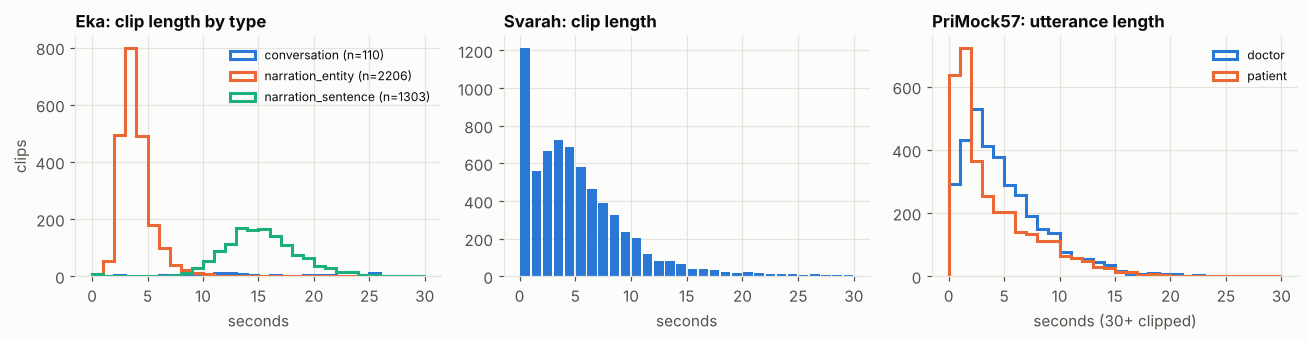

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
ax = axes[0]
for i, (k, g) in enumerate(eka.groupby('recording_context')):
    ax.hist(g.duration_seconds, bins=np.arange(0, 31, 1), histtype='step', lw=2, color=S[i], label=f'{k} (n={len(g)})')
ax.set_title('Eka: clip length by type'); ax.set_xlabel('seconds'); ax.set_ylabel('clips'); ax.legend(fontsize=8)
ax = axes[1]; ax.hist(sv.duration_seconds, bins=np.arange(0, 31, 1), color=S[0], rwidth=0.85)
ax.set_title('Svarah: clip length'); ax.set_xlabel('seconds')
ax = axes[2]
for i, (k, g) in enumerate(utt.groupby('speaker_role')):
    ax.hist(g.duration_seconds.clip(upper=30), bins=np.arange(0, 31, 1), histtype='step', lw=2, color=S[i], label=k)
ax.set_title('PriMock57: utterance length'); ax.set_xlabel('seconds (30+ clipped)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '01_durations.png'); plt.show()

## 2. PriMock57: how the consultations behave

In [4]:
rows = []
for cid, r in refs.items():
    d = [(s['start'], s['end']) for s in r['segments'] if s['speaker'] == 'doctor']
    p = [(s['start'], s['end']) for s in r['segments'] if s['speaker'] == 'patient']
    ov = sum(max(0, min(b, y) - max(a, x)) for a, b in d for x, y in p)
    rows.append(dict(consultation=cid, split=r['split'], minutes=r['duration_s'] / 60,
                     doctor_share=sum(b - a for a, b in d) / (sum(b - a for a, b in d) + sum(y - x for x, y in p)),
                     overlap_pct=100 * ov / r['duration_s'], turns=len(r['segments'])))
pm = pd.DataFrame(rows)
wpm = (utt.groupby('speaker_role').n_words.sum() / (utt.groupby('speaker_role').duration_seconds.sum() / 60)).rename('words_per_min')
roles = utt.groupby('speaker_role').agg(utterances=('sample_id', 'size'), median_words=('n_words', 'median'),
                                       median_s=('duration_seconds', 'median'), unsure_pct=('unsure', 'mean'),
                                       unintelligible_pct=('unintelligible', 'mean')).join(wpm)
roles[['unsure_pct', 'unintelligible_pct']] *= 100
roles = roles.round(1); roles.to_csv(TAB / '02_primock_roles.csv'); display(roles)
display(pm[['minutes', 'doctor_share', 'overlap_pct', 'turns']].describe().round(2).loc[['mean', '50%', 'min', 'max']])

,utterances,median_words,median_s,unsure_pct,unintelligible_pct,words_per_min
speaker_role,,,,,,
doctor,3404,11.0,4.1,15.0,19.4,173.6
patient,3147,6.0,2.5,15.1,14.8,150.5


,minutes,doctor_share,overlap_pct,turns
mean,9.09,0.59,4.83,118.28
50%,9.32,0.59,4.00,120.00
min,3.81,0.37,1.45,49.00
max,14.30,0.77,13.93,165.00


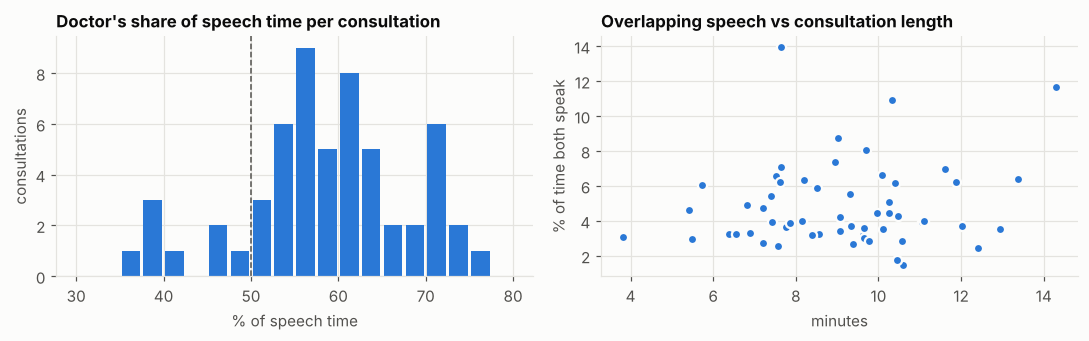

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ax = axes[0]; ax.hist(100 * pm.doctor_share, bins=np.arange(30, 81, 2.5), color=S[0], rwidth=0.85)
ax.axvline(50, color=INK2, lw=1, ls='--'); ax.set_title("Doctor's share of speech time per consultation"); ax.set_xlabel('% of speech time'); ax.set_ylabel('consultations')
ax = axes[1]; ax.scatter(pm.minutes, pm.overlap_pct, s=36, color=S[0], edgecolor=SURF, lw=1.5)
ax.set_title('Overlapping speech vs consultation length'); ax.set_xlabel('minutes'); ax.set_ylabel('% of time both speak')
fig.tight_layout(); fig.savefig(FIG / '02_primock_structure.png'); plt.show()

## 3. Eka: numbers, units and medical terms

This decides the open scoring rule (how "500 mg" vs "five hundred milligrams" is scored). **Decisions use dev only**; the full-set column is shown for context.

In [6]:
PAT = {'any digit': r'\d', 'digit + unit (mg, ml, mcg, g, iu)': r'\b\d+\s*(?:mg|ml|mcg|g|gm|iu|units?)\b',
       'ordinal (3rd, 22nd)': r'\b\d+(?:st|nd|rd|th)\b',
       'number written as a word': r'\b(?:one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|fifteen|twenty|hundred|thousand)\b',
       'once / twice / thrice': r'\b(?:once|twice|thrice)\b', 'dosing abbreviation (OD, BD, TDS, SOS)': r'\b(?:od|bd|bid|tds|tid|qid|hs|sos|prn|stat)\b'}
dev = eka[eka.split == 'dev']
num = pd.DataFrame({k: {'dev %': 100 * dev.transcript.str.contains(p, case=False, regex=True).mean(),
                        'all %': 100 * eka.transcript.str.contains(p, case=False, regex=True).mean()} for k, p in PAT.items()}).T.round(1)
drug_digit = lambda l: any(t['type'] == 'drugs' and re.search(r'\d', t['text']) for t in json.loads(l))
num.loc['drug name containing digits (Dolo 650), from entity tags'] = [100 * dev.medical_entities.map(drug_digit).mean(), 100 * eka.medical_entities.map(drug_digit).mean()]
num = num.round(1); num.to_csv(TAB / '03_eka_numbers.csv'); display(num)
print('transcripts entirely in capitals:', round(100 * (eka.transcript.str.upper() == eka.transcript).mean(), 1), '%')
print('\nDev examples with units:')
for t in dev[dev.transcript.str.contains(PAT['digit + unit (mg, ml, mcg, g, iu)'], case=False, regex=True)].transcript.head(6): print(' -', t[:150])

,dev %,all %
any digit,49.5,47.6
"digit + unit (mg, ml, mcg, g, iu)",20.1,20.5
"ordinal (3rd, 22nd)",0.1,0.2
number written as a word,4.9,3.9
once / twice / thrice,0.3,0.7
"dosing abbreviation (OD, BD, TDS, SOS)",0.5,0.6
"drug name containing digits (Dolo 650), from entity tags",33.2,32.8


transcripts entirely in capitals: 0.9 %

Dev examples with units:
 - Libotryp 12.5 Mg by 5 Mg Tablet
 - Pantin 40Mg Tablet
 - Syndopa Plus 100mg by 25mg Tablet
 - Pantosec D 10mg by 40mg Tablet
 - Aceclo Plus 100mg by 325mg Tablet
 - Ketorol Dt 10mg


context,conversation,narration_entity,narration_sentence,total
type,,,,
clinical_findings,177,852,4586,5615
drugs,140,1097,1267,2504
misc_medical,20,0,1125,1145
diagnostics,51,56,914,1021
advices,130,201,45,376


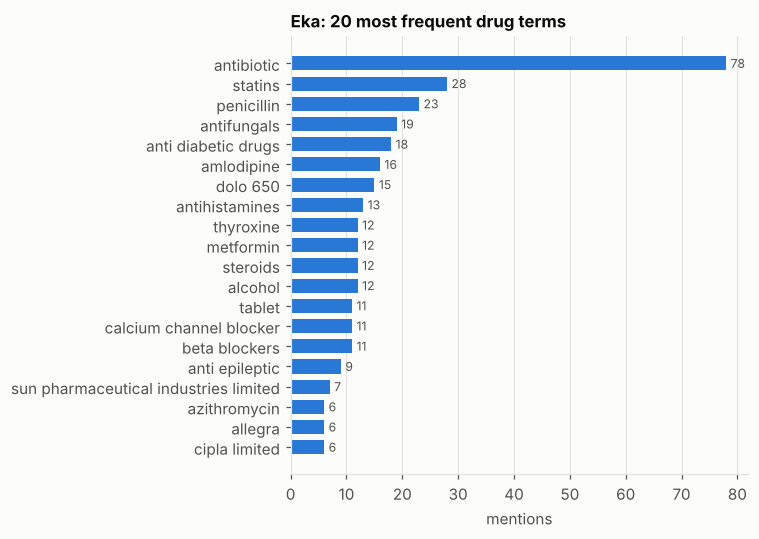

distinct drug terms: 1891


In [7]:
ents = pd.DataFrame([dict(sample_id=r.sample_id, split=r.split, context=r.recording_context, **e)
                     for r in eka.itertuples() for e in json.loads(r.medical_entities)])
by_type = ents.pivot_table(index='type', columns='context', values='sample_id', aggfunc='count', fill_value=0)
by_type['total'] = by_type.sum(axis=1); by_type = by_type.sort_values('total', ascending=False); by_type.to_csv(TAB / '03_eka_entity_types.csv'); display(by_type)
top = ents[ents.type == 'drugs'].norm.value_counts().head(20)
fig, ax = plt.subplots(figsize=(7, 5)); ax.barh(top.index[::-1], top.values[::-1], color=S[0], height=0.7)
for y, v in enumerate(top.values[::-1]): ax.text(v + 0.8, y, str(v), va='center', fontsize=8, color=INK2)
ax.set_title('Eka: 20 most frequent drug terms'); ax.set_xlabel('mentions'); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / '03_eka_top_drugs.png'); plt.show()
print('distinct drug terms:', ents[ents.type == 'drugs'].norm.nunique())

## 4. Svarah: who is speaking

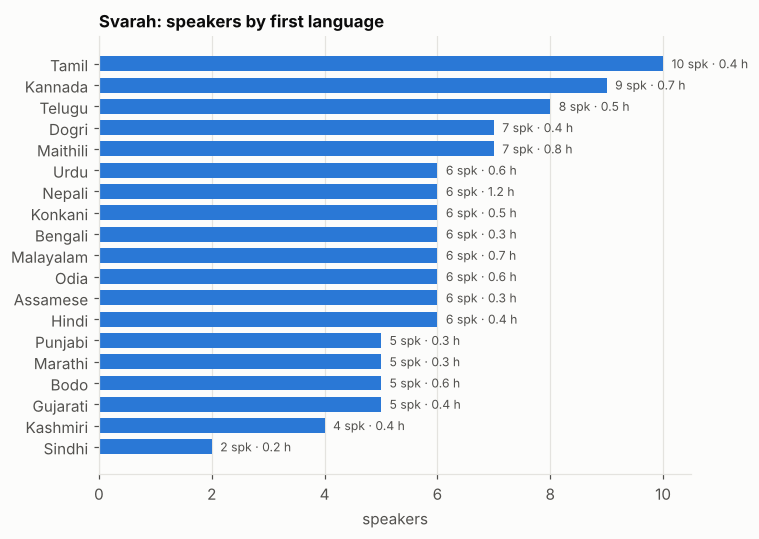

states: 17 | gender: {'Female': 62, 'Male': 53} | age: {'30-45': 41, '18-30': 37, '45-60': 27, '60+': 10}
dev first languages: ['Assamese', 'Bengali', 'Bodo', 'Dogri', 'Gujarati', 'Hindi', 'Kannada', 'Maithili', 'Malayalam', 'Marathi', 'Nepali', 'Odia', 'Tamil', 'Telugu', 'Urdu']


In [8]:
spk = sv.drop_duplicates('speaker_id')
l1 = sv.groupby('primary_language').agg(speakers=('speaker_id', 'nunique'), hours=('duration_seconds', lambda x: x.sum() / 3600)).sort_values('speakers')
l1.round(2).to_csv(TAB / '04_svarah_l1.csv')
fig, ax = plt.subplots(figsize=(7, 5)); ax.barh(l1.index, l1.speakers, color=S[0], height=0.7)
for y, (v, h) in enumerate(zip(l1.speakers, l1.hours)): ax.text(v + 0.15, y, f'{v} spk · {h:.1f} h', va='center', fontsize=8, color=INK2)
ax.set_title("Svarah: speakers by first language"); ax.set_xlabel('speakers'); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / '04_svarah_l1.png'); plt.show()
print('states:', spk.native_state.nunique(), '| gender:', spk.gender.value_counts().to_dict(), '| age:', spk.age_group.value_counts().to_dict())
print('dev first languages:', sorted(sv[sv.split == 'dev'].primary_language.unique()))

In [9]:
short = pd.DataFrame({d: {'clips < 1 s %': 100 * (x.duration_seconds < 1).mean(), 'clips with <= 2 words %': 100 * (x.n_words <= 2).mean(),
                             'hours in clips <= 2 words': x[x.n_words <= 2].duration_seconds.sum() / 3600}
                      for d, x in (('Svarah', sv), ('Eka', eka), ('PriMock57 utterances', utt))}).T.round(2)
short.to_csv(TAB / '04_short_clips.csv'); display(short)
print('Most common Svarah clips under 1 s:', sv[sv.duration_seconds < 1].transcript.value_counts().head(10).to_dict())

,clips < 1 s %,clips with <= 2 words %,hours in clips <= 2 words
Svarah,18.24,21.50,0.30
Eka,0.22,22.46,0.73
PriMock57 utterances,14.18,21.84,0.41


Most common Svarah clips under 1 s: {'Jump': 30, 'Play': 29, 'Skip': 28, 'Visual': 27, 'House': 27, 'Forward': 26, 'Two': 26, 'Backward': 25, 'Cat': 25, 'Up': 25}


## 5. Noisy versions: are the levels what they claim?

Re-measures every **dev** noisy file: interference = noisy file (undoing the peak scaling) minus the clean consultation, compared with the consultation's annotated speech. Interference power is taken over the background talker's speech (its annotated utterances for British talkers, its voiced samples for Indian talkers) and over the whole file for noise, matching how the levels were set. Takes a few minutes.

In [10]:
def active_idx(r, n, sr=16000):
    return np.concatenate([np.arange(int(s['start'] * sr), min(int(s['end'] * sr), n)) for s in r['segments']])
meas = []
for cid in sorted(noisy[noisy.split == 'dev'].source_consultation.unique()):
    clean, _ = sf.read(DATA / f'primock57/mixed/{cid}.wav', dtype='float32'); idx = active_idx(refs[cid], len(clean)); pt = np.mean(clean[idx] ** 2)
    for r in noisy[noisy.source_consultation == cid].itertuples():
        m = json.loads(r.mix_meta); y, _ = sf.read(DATA / r.relative_audio_path, dtype='float32')
        res = y / m['peak_scale'] - clean
        if r.condition.startswith('talker_sir'):
            # British talker = another PriMock57 consultation: use ITS annotated speech, shifted and looped exactly as mixed
            did = m['distractor']; dl = int(round(refs[did]['duration_s'] * 16000)); off = int(round(m['distractor_offset_s'] * 16000))
            src = np.zeros(dl, bool); src[active_idx(refs[did], dl)] = True
            mask = np.tile(np.roll(src, -off), int(np.ceil(len(clean) / dl)))[:len(clean)]
            p = np.mean(res[mask] ** 2)
        elif r.condition.startswith('talker_in'):
            p = np.mean(res[np.abs(res) > 1e-4] ** 2)     # Indian talker: voiced samples only (pauses are digital silence)
        else:
            p = np.mean(res ** 2)                          # noise: whole file
        meas.append(dict(consultation=cid, condition=r.condition, measured_db=10 * np.log10(pt / p),
                         nominal_db=r.sir_db if r.condition.startswith('talker') else (r.snr_db if not r.condition.startswith('opd') else np.nan),
                         clipped_peak_scale=m['peak_scale']))
meas = pd.DataFrame(meas)
lv = meas.groupby('condition').agg(nominal_db=('nominal_db', 'first'), measured_mean=('measured_db', 'mean'),
                                   measured_min=('measured_db', 'min'), measured_max=('measured_db', 'max'),
                                   min_peak_scale=('clipped_peak_scale', 'min')).round(2)
lv.to_csv(TAB / '05_noise_levels_dev.csv'); lv

,nominal_db,measured_mean,measured_min,measured_max,min_peak_scale
condition,,,,,
noise_snr10,10.0,10.00,10.00,10.00,0.96
noise_snr20,20.0,20.00,20.00,20.00,1.00
noise_snr5,5.0,5.00,5.00,5.00,0.69
opd_sir5_snr10,NaN,4.06,3.76,4.42,0.80
talker_in_sir0,0.0,0.02,-0.01,0.08,0.61
talker_in_sir10,10.0,9.89,9.79,9.96,0.93
talker_in_sir5,5.0,4.98,4.93,5.04,0.78
talker_sir0,0.0,-0.04,-0.20,0.16,0.62
talker_sir10,10.0,9.96,9.80,10.16,0.94


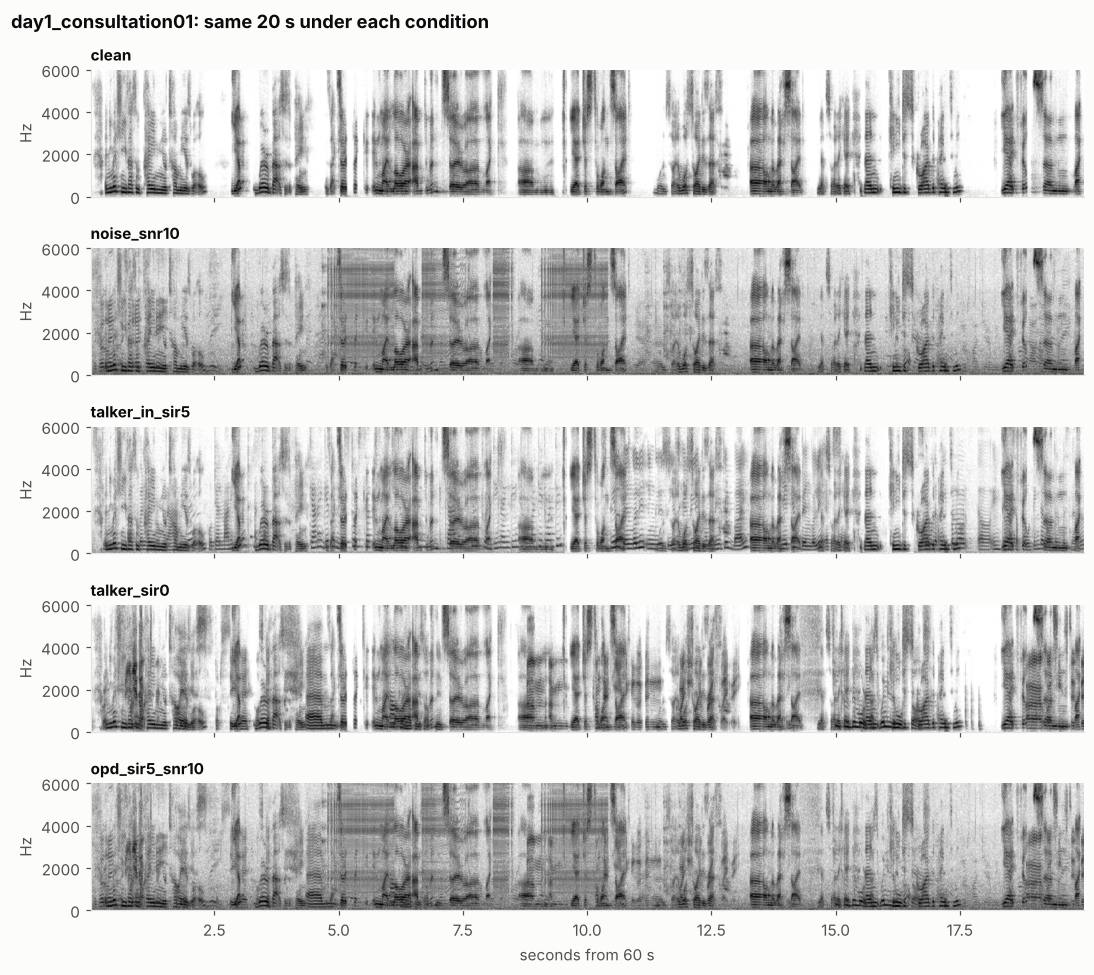

In [11]:
cid = 'day1_consultation01'; t0, t1, sr = 60, 80, 16000
conds = ['clean', 'noise_snr10', 'talker_in_sir5', 'talker_sir0', 'opd_sir5_snr10']
fig, axes = plt.subplots(len(conds), 1, figsize=(10, 9), sharex=True)
for ax, c in zip(axes, conds):
    p = DATA / (f'primock57/mixed/{cid}.wav' if c == 'clean' else f'primock57/noisy/{cid}__{c}.flac')
    y, _ = sf.read(p, dtype='float32', start=t0 * sr, stop=t1 * sr)
    ax.specgram(y, NFFT=512, Fs=sr, noverlap=384, cmap='Greys', vmin=-120, vmax=-30); ax.set_ylim(0, 6000)
    ax.set_ylabel('Hz'); ax.set_title(c, fontsize=10); ax.grid(False)
axes[-1].set_xlabel(f'seconds from {t0} s'); fig.suptitle(f'{cid}: same 20 s under each condition', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / '05_spectrograms.png'); plt.show()

## 6. Vocabulary gap: words models are likely to miss

A term is counted as **rare** when it has (almost) no frequency in general English text (`wordfreq` Zipf < 1.5, i.e. under ~3 per 100 million words). Indian brand names should dominate.

In [12]:
def rare(term): return any(zipf_frequency(w, 'en') < 1.5 for w in re.findall(r'[a-z]+', term) if len(w) > 2)
ents['rare'] = ents.norm.map(rare)
gap = ents.groupby('type').agg(mentions=('norm', 'size'), rare_pct=('rare', 'mean')); gap['rare_pct'] *= 100
gap = gap.round(1).sort_values('rare_pct', ascending=False); gap.to_csv(TAB / '06_vocab_gap.csv'); display(gap)
rd = ents[ents.rare & (ents.type == 'drugs')].norm.value_counts().head(25)
print('Most frequent rare drug terms:', ', '.join(rd.index))
pm_words = collections.Counter(w for t in utt.transcript_norm.fillna('') for w in t.split())
print('PriMock57: share of word tokens that are rare in general English:',
      round(100 * sum(v for w, v in pm_words.items() if zipf_frequency(w, 'en') < 1.5) / sum(pm_words.values()), 2), '%')

,mentions,rare_pct
type,,
drugs,2504,59.6
diagnostics,1021,10.9
advices,376,10.6
clinical_findings,5615,6.5
misc_medical,1145,3.5


Most frequent rare drug terms: intas pharmaceuticals limited, ipca laboratories limited, ethambutol, azoran, zincovit, volini, alkem laboratories limited, macleods pharmaceuticals private limited, systopic laboratories private limited, embramine, zydus cadila, aflapin, etoshift 90mg tablet, bifolate tablet, levocarnitine, glycomet trio 2, zuventus healthcare limited, tapentadol, mianserin, atracurium, trihexyphenidyl, pantop dsr, gelusil tablet, pantop dsr 40, pataday
PriMock57: share of word tokens that are rare in general English: 0.17 %


## 7. Findings and decisions

**What the models will face**

| | Finding | Consequence |
|---|---|---|
| PriMock57 | Doctors hold 59% of annotated speech time (37–77% per consultation) and speak faster than patients (174 vs 151 words per minute of annotated utterance time); patient utterances are short (median 6 words, 2.5 s). Doctor and patient utterances overlap for 4.8% of the consultation on average (up to 13.9%). | Report WER separately for doctor and patient. Overlap is real even in the clean set. |
| PriMock57 | 19% of doctor and 15% of patient utterances contain an unintelligible span; 15% contain an uncertain one. | Keep them in the main score; add a strict score that excludes flagged utterances. |
| Eka | Half of all transcripts (49.5% of dev) contain digits; a third contain a drug name with digits ("Dolo 650"); 20% have a number with a unit, written inconsistently ("40Mg", "100mg", "12.5 Mg"); about 5% have numbers as words. Ordinals and dosing abbreviations are rare (< 1%). | Numbers and units need a scoring rule (below), or dosage clips are penalised for formatting. |
| Eka | 60% of drug mentions contain a word that is rare in general English (Zincovit, Pantop DSR, Glycomet Trio…); only 4–11% of other term types do. Some "drug" entities are manufacturer names (Intas Pharmaceuticals Limited). | Drug names are where models will fail. Report drug-term accuracy separately from WER. |
| Eka | Single-term clips mostly run 2.5–6 s, sentences 11–20 s (10th–90th percentile); only 110 conversation clips, whose speakers are not identified. | Report WER per clip type, never one Eka number. |
| Svarah | 18% of clips are under 1 s, and 93% of those are a single word ("Jump", "Play", "Skip"); 115 speaker profiles (about 117 speakers), 19 first languages, 17 states in the metadata (the dataset card says 19). | Use pooled (corpus-level) WER, not the mean of per-clip WER, so one-word clips don't dominate. |
| Noisy set | Every condition measures on target: noise exactly, Indian talker within 0.2 dB, British talker within 0.2 dB. Busy OPD measures 4.1 dB (3.8–4.4); 5 dB talker plus 10 dB noise should combine to 3.8 dB, and the small gap comes from measuring the talker over the whole file in this condition. | Levels can be quoted as labelled. |
| Vocabulary | Only 0.17% of PriMock57 words are rare in general English. | PriMock57 tests noise and conversation; Eka tests medical vocabulary. They answer different questions. |

**Proposed scoring rule v2 (from the dev split)**, applied identically to reference and model output:

1. Split numbers from units: "40Mg" → "40 mg".
2. Map unit words to one form: milligram(s) → mg, millilitre/milliliter(s) → ml, microgram(s) → mcg, gram(s) → g.
3. Convert number words to digits: "five hundred" → "500", "two" → "2".
4. Leave "once / twice / thrice" and dosing abbreviations as they are (under 1% of clips).

Still to decide: whether "times a day" phrasing ("2 times in a day" vs "twice a day") should count as equal. It is rare here, so it can wait for the first model outputs.